# 01 - Dataset Exploration

Exploratory analysis of the RIM-ONE DL dataset, focusing on class distribution, image properties, and visual inspection of retinal fundus images.

## 1. Environment Setup

Import the required libraries and define the paths to the training and test datasets.

In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

# Project and dataset paths
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data/raw/rim_one_dl/partitioned_randomly"

TRAIN_DIR = DATA_DIR / "training_set"
TEST_DIR = DATA_DIR / "test_set"

CLASSES = ["normal", "glaucoma"]

print("Dataset found:", DATA_DIR.is_dir())

Dataset found: True


## 2. Class Distribution

Analyze the number of images in each class and dataset split to identify potential class imbalance.

In [20]:
# Count images in each dataset split
for split_name, split_dir in [
    ("Training", TRAIN_DIR),
    ("Test", TEST_DIR)
]:
    print(f"\n{split_name} set:")

    for class_name in CLASSES:
        class_dir = split_dir / class_name

        images = [
            path for path in class_dir.iterdir()
            if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
        ]

        print(f"  {class_name}: {len(images)} images")


Training set:
  normal: 219 images
  glaucoma: 120 images

Test set:
  normal: 94 images
  glaucoma: 52 images


## 3. Image Visualization

Visualize sample fundus images from both classes and inspect their dimensions and color representations.

normal:
  Dimensions: (462, 462)
  Color mode: RGB
glaucoma:
  Dimensions: (547, 547)
  Color mode: RGB


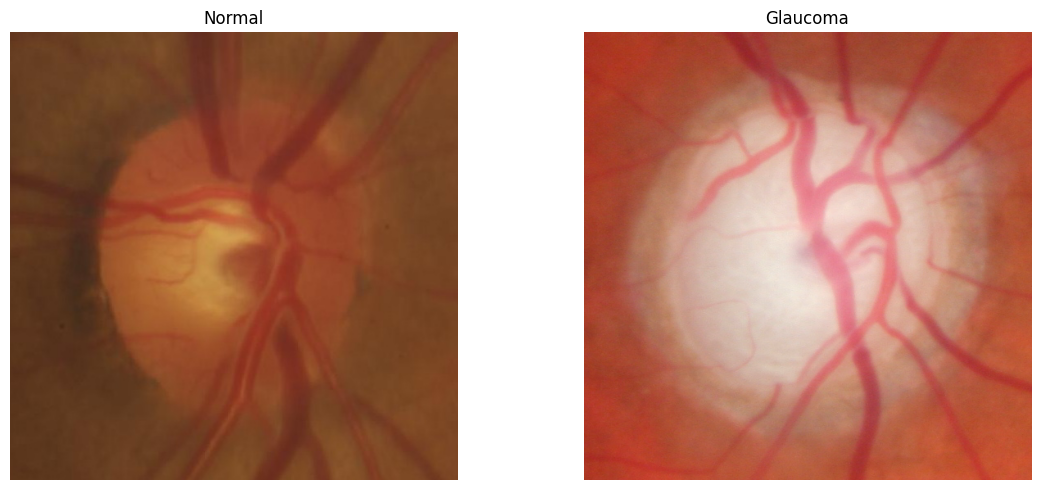

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, class_name in zip(axes, CLASSES):
    class_dir = TRAIN_DIR / class_name

    image_path = next(
        path for path in sorted(class_dir.iterdir())
        if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    )

    with Image.open(image_path) as image:
        print(f"{class_name}:")
        print(f"  Dimensions: {image.size}")
        print(f"  Color mode: {image.mode}")

        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Image Representation

Explore how digital images are represented as multidimensional NumPy arrays, examining their shapes, data types, and pixel values.

In [22]:
import numpy as np

# Select a sample image
class_dir = TRAIN_DIR / "normal"

image_path = next(
    path for path in sorted(class_dir.iterdir())
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
)

# Convert the image to a NumPy array
with Image.open(image_path) as image:
    image_array = np.array(image.convert("RGB"))

print("Shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("First pixel:", image_array[0, 0])
print("Center pixel:", image_array[
    image_array.shape[0] // 2,
    image_array.shape[1] // 2
])

Shape: (462, 462, 3)
Data type: uint8
First pixel: [100  55  32]
Center pixel: [162  84  48]


## 5. RGB Channel Analysis

Separate and visualize the RGB color channels to investigate their individual intensity distributions and structural characteristics.

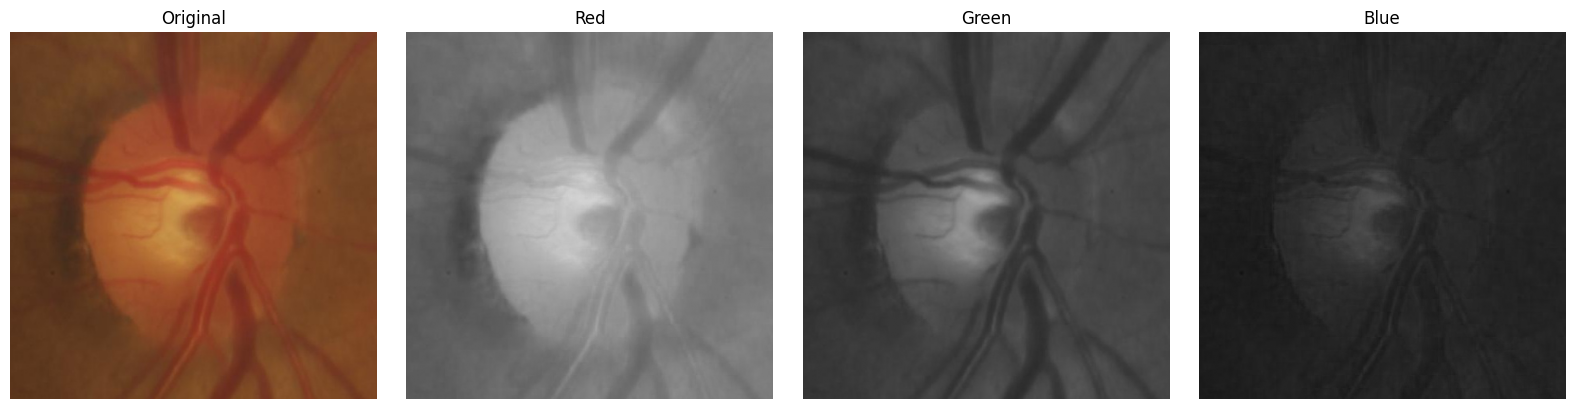

In [23]:
# Extract RGB channels
red_channel = image_array[:, :, 0]
green_channel = image_array[:, :, 1]
blue_channel = image_array[:, :, 2]

# Create a figure with four subplots
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

images = [
    image_array,
    red_channel,
    green_channel,
    blue_channel
]

titles = ["Original", "Red", "Green", "Blue"]

for ax, img, title in zip(axes, images, titles):
    if title == "Original":
        ax.imshow(img)
    else:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Intensity Distribution Analysis

Analyze the intensity distributions of individual RGB channels using histograms to investigate differences in contrast and pixel values.

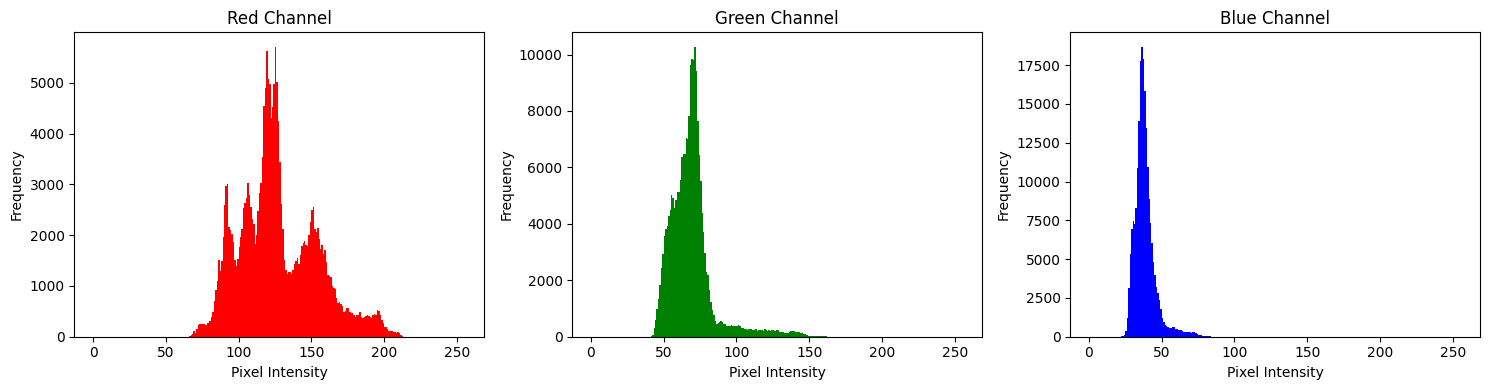

In [24]:
# Create a figure for RGB histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

channels = ["Red", "Green", "Blue"]
colors = ["red", "green", "blue"]

for i, (ax, channel, color) in enumerate(zip(axes, channels, colors)):
    pixels = image_array[:, :, i].ravel()

    ax.hist(pixels, bins=256, range=(0, 256), color=color)

    ax.set_title(f"{channel} Channel")
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.1. Global and Local Intensity Variations

Compare global intensity dispersion and local pixel differences across RGB channels to investigate how spatial information complements histogram analysis.

In [25]:
# Compare global and local intensity variations
channels = {
    "Red": red_channel,
    "Green": green_channel,
    "Blue": blue_channel
}

for name, channel in channels.items():
    channel = channel.astype(np.float32)

    # Global intensity variation
    global_std = np.std(channel)

    # Local differences between adjacent pixels
    horizontal_diff = np.abs(np.diff(channel, axis=1))
    vertical_diff = np.abs(np.diff(channel, axis=0))

    local_variation = (horizontal_diff.mean() + vertical_diff.mean()) / 2

    print(f"{name} Channel:")
    print(f"  Global std: {global_std:.2f}")
    print(f"  Mean local variation: {local_variation:.2f}\n")

Red Channel:
  Global std: 26.75
  Mean local variation: 0.73

Green Channel:
  Global std: 16.05
  Mean local variation: 0.71

Blue Channel:
  Global std: 7.57
  Mean local variation: 0.70



## 7. Image Properties Analysis

Examine image dimensions, color modes, and file formats across the dataset to identify inconsistencies and potential acquisition-related biases.

In [26]:
import pandas as pd

image_records = []

for split_name, split_dir in [
    ("Training", TRAIN_DIR),
    ("Test", TEST_DIR)
]:
    for class_name in CLASSES:
        class_dir = split_dir / class_name

        for image_path in sorted(class_dir.iterdir()):
            if image_path.suffix.lower() not in {
                ".jpg", ".jpeg", ".png", ".tif", ".tiff"
            }:
                continue

            with Image.open(image_path) as image:
                width, height = image.size

                image_records.append({
                    "split": split_name,
                    "class": class_name,
                    "width": width,
                    "height": height,
                    "mode": image.mode,
                    "format": image.format
                })

df = pd.DataFrame(image_records)

display(df.head())

,split,class,width,height,mode,format
0,Training,normal,462,462,RGB,PNG
1,Training,normal,524,524,RGB,PNG
2,Training,normal,476,476,RGB,PNG
3,Training,normal,316,316,RGB,PNG
4,Training,normal,496,496,RGB,PNG


In [31]:
# Image dimensions by dataset split and class
print(
    df.groupby(["split", "class"])[["width", "height"]]
      .agg(["min", "median", "max"])
)

# Color mode distribution
print("\nColor modes:")
print(df["mode"].value_counts())

# File format distribution
print("\nFile formats:")
print(df["format"].value_counts())

print("\nAll images are square:", (df["width"] == df["height"]).all())

                  width             height            
                    min median  max    min median  max
split    class                                        
Test     glaucoma   342  497.5  793    342  497.5  793
         normal     296  459.0  766    296  459.0  766
Training glaucoma   274  468.5  790    274  468.5  790
         normal     306  452.0  766    306  452.0  766

Color modes:
mode
RGB    485
Name: count, dtype: int64

File formats:
format
PNG    485
Name: count, dtype: int64

All images are square: True


## 8. Dataset-Wide Visual Inspection

Visually inspect multiple samples from each class to identify differences in image appearance, illumination, anatomical structures, and potential acquisition-related biases.

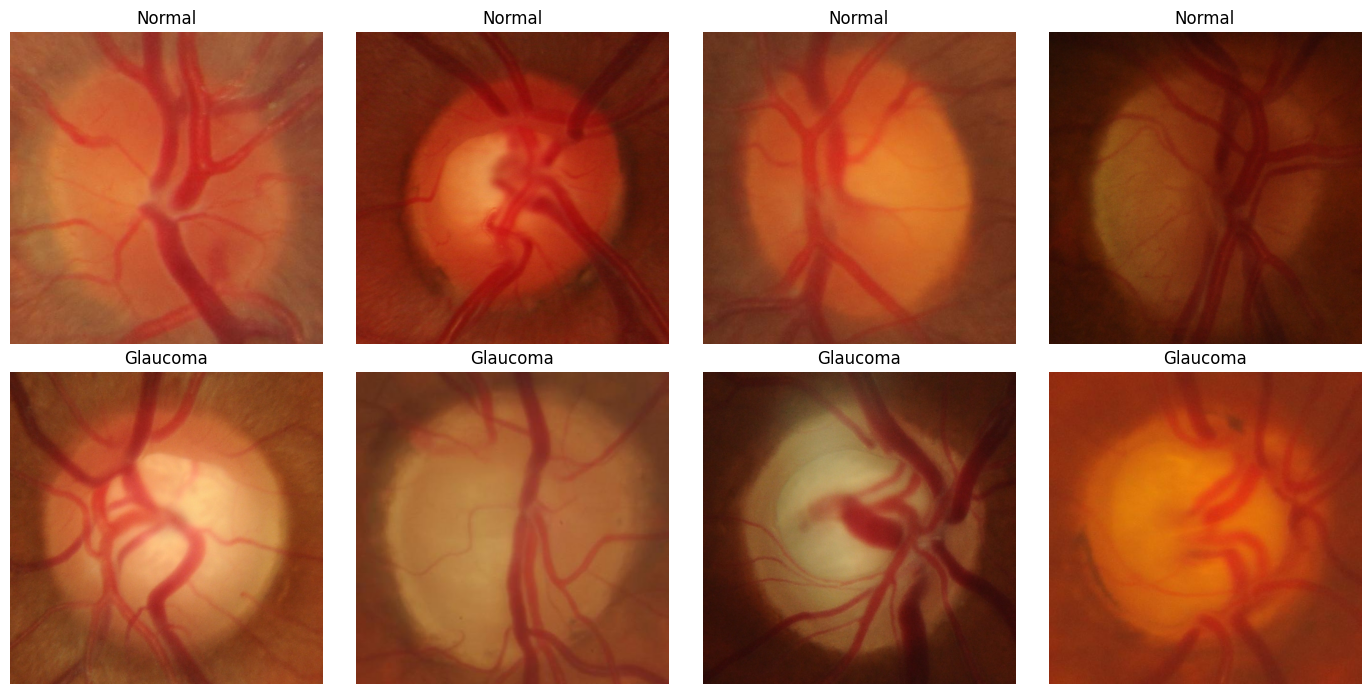

In [32]:
import random

# Initialize a reproducible random generator
rng = random.Random(50)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, class_name in enumerate(CLASSES):
    class_dir = TRAIN_DIR / class_name

    image_paths = sorted(
        path for path in class_dir.iterdir()
        if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    )

    # Randomly select four images from each class
    selected_images = rng.sample(image_paths, 4)

    for col, image_path in enumerate(selected_images):
        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].set_title(class_name.capitalize())
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## 9. Data Quality and Integrity

Check for corrupted image files and exact duplicates, including potential data leakage between training and test sets.

In [34]:
import hashlib

# Store image hashes and detected issues
seen_hashes = {}
duplicates = []
corrupted = []

for split_name, split_dir in [
    ("Training", TRAIN_DIR),
    ("Test", TEST_DIR)
]:
    for class_name in CLASSES:
        class_dir = split_dir / class_name

        for image_path in sorted(class_dir.iterdir()):
            if image_path.suffix.lower() not in {
                ".jpg", ".jpeg", ".png", ".tif", ".tiff"
            }:
                continue

            try:
                # Check whether the image can be decoded
                with Image.open(image_path) as image:
                    image.load()

                # Calculate the file's SHA-256 hash
                image_hash = hashlib.sha256(
                    image_path.read_bytes()
                ).hexdigest()

                image_info = (split_name, class_name, image_path.name)

                if image_hash in seen_hashes:
                    duplicates.append((seen_hashes[image_hash], image_info))
                else:
                    seen_hashes[image_hash] = image_info

            except (OSError, ValueError) as error:
                corrupted.append((str(image_path), str(error)))

print("Corrupted images:", len(corrupted))
print("Exact duplicate files:", len(duplicates))
print("Duplicates:", duplicates)

Corrupted images: 0
Exact duplicate files: 0
Duplicates: []
